# 3.2 Texte OCR + similarité cosinus : Dataset 1

OCR (Tesseract), puis TF-IDF (mots ou morceaux de 3 à 5 caractères), puis centroïde le plus proche
au sens du cosinus, comme pour les pixels.

In [1]:
import os

import cv2
import matplotlib.pyplot as plt
import pandas as pd
import pytesseract
import seaborn as sns
from nltk.corpus import stopwords
from PIL import Image
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

from outils_3 import list_images, classify_by_cosine

DOSSIER = "../data/document-classification-dataset_1"
CORPUS_OCR = "../data/artifacts_document-classification-dataset_1/ocr_corpus.csv"

## 1. L'OCR, étape par étape, sur une image

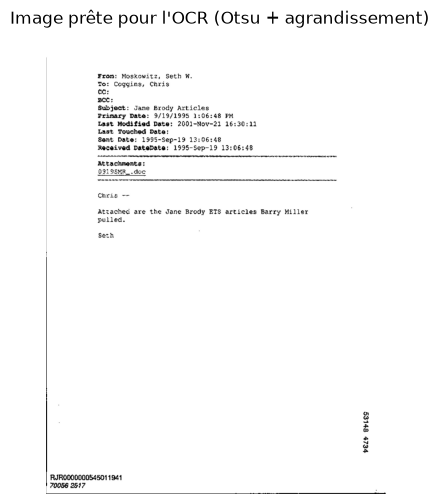

From: Moskowitz, Seth W. To: Coggins, Chris ce: BCC: Subject: Jane Brody Articles Primary Date: 9/19/1995 1:06:48 PM Last Modified Date: 2001-Nov-21 16:30:11 Last Touched Data: Sent Date: 1995-Sep-19 13:06:48 Received 1995-Sep-19 13:06:48 Attachments: SSMR_.doc Chris are the Jane Brody ETS articles Barry Miller pulled. Seth . 1941


In [2]:
image = cv2.imread(DOSSIER + "/email/doc_000042.png", cv2.IMREAD_GRAYSCALE)

# 1. noir et blanc (otsu)
_, image = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 2. on agrandit, Tesseract lit mieux les gros caractères
hauteur, largeur = image.shape
if largeur < 1500:
    echelle = 1500 / largeur
    image = cv2.resize(image, (int(largeur * echelle), int(hauteur * echelle)), interpolation=cv2.INTER_CUBIC)

# 3. Tesseract, en ne gardant que les mots dont il est assez sûr
donnees = pytesseract.image_to_data(image, lang="eng", config="--psm 6", output_type=pytesseract.Output.DICT)
mots = [mot.strip() for mot, confiance in zip(donnees["text"], donnees["conf"])
        if mot.strip() and float(confiance) >= 60]

plt.figure(figsize=(5, 6))
plt.imshow(image, cmap="gray")
plt.title("Image prête pour l'OCR (Otsu + agrandissement)")
plt.axis("off")
plt.show()
print(" ".join(mots)[:400])

## 2. Le corpus OCR des 165 images

Le texte a été lu une fois (1 seconde par image) et enregistré dans un CSV.

In [3]:
textes = pd.read_csv(CORPUS_OCR, keep_default_na=False)
texte_par_fichier = dict(zip(textes["filepath"].map(os.path.basename), textes["text"]))

# même ordre que pour les pixels, donc même découpage
df = list_images(DOSSIER)
df["text"] = df["filepath"].map(os.path.basename).map(texte_par_fichier)

MOTS_VIDES = stopwords.words("english")
df["texte_sans_mots_vides"] = df["text"].apply(
    lambda texte: " ".join(mot for mot in texte.split() if mot.lower() not in MOTS_VIDES))

train_df, test_df = train_test_split(df, test_size=0.2, random_state=1, stratify=df["label"])
print(f"Train : {len(train_df)} | Test : {len(test_df)}")
df["text"].str.split().str.len().groupby(df["label"]).describe()[["mean", "min", "max"]]

Train : 132 | Test : 33


,mean,min,max
label,,,
email,91.836364,13.0,461.0
resume,280.418182,6.0,502.0
scientific_publication,461.163636,19.0,779.0


## 3. Quatre variantes TF-IDF + centroïdes + cosinus

Mots ou caractères ? Avec ou sans les mots vides (the, of, and…) ?

In [4]:
variantes = {
    # nom : (vectoriseur, colonne de texte)
    "mots": (TfidfVectorizer(ngram_range=(1, 2), strip_accents="unicode", sublinear_tf=True), "text"),
    "mots, sans mots vides": (TfidfVectorizer(ngram_range=(1, 2), strip_accents="unicode", sublinear_tf=True,
                                              stop_words=MOTS_VIDES), "text"),
    "caractères": (TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True), "text"),
    "caractères, sans mots vides": (TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True),
                                    "texte_sans_mots_vides"),
}

lignes, predictions = [], {}
for nom, (vectoriseur, colonne) in variantes.items():
    X_train = vectoriseur.fit_transform(train_df[colonne])  # fit sur le train seulement
    X_test = vectoriseur.transform(test_df[colonne])
    predictions[nom], _ = classify_by_cosine(X_train, train_df["label"], X_test)
    lignes.append({"variante": nom, "taille du vocabulaire": len(vectoriseur.vocabulary_),
                   "accuracy": accuracy_score(test_df["label"], predictions[nom])})

pd.DataFrame(lignes).round(3)

,variante,taille du vocabulaire,accuracy
0,mots,37216,0.909
1,"mots, sans mots vides",31520,1.000
2,caractères,70393,0.939
3,"caractères, sans mots vides",70168,0.970


## 4. Matrices de confusion : mots / caractères

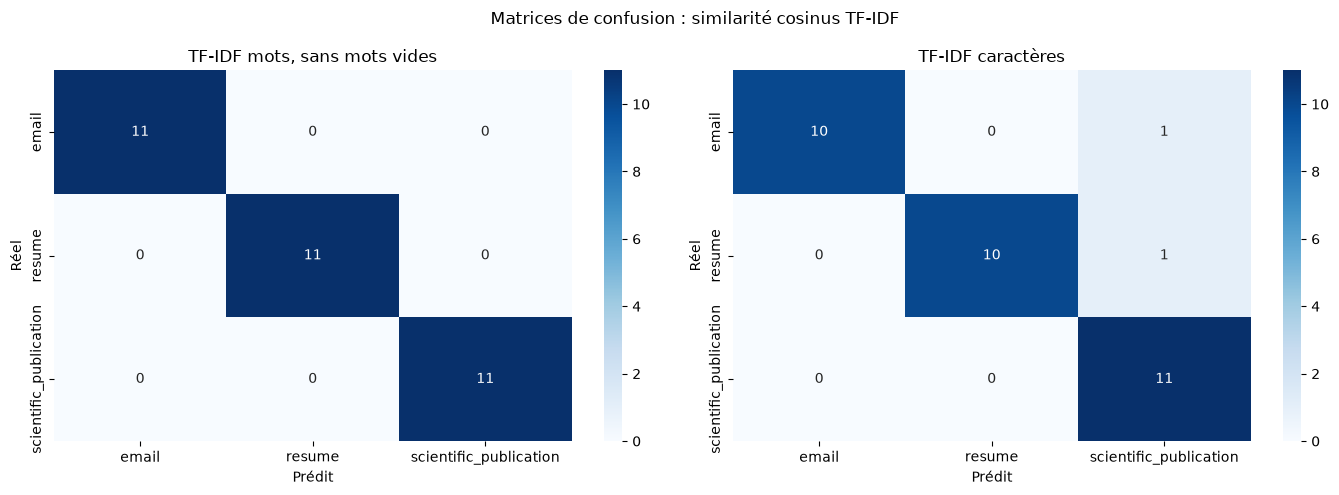

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, nom in zip(axes, ["mots, sans mots vides", "caractères"]):
    matrice = pd.crosstab(test_df["label"], predictions[nom], rownames=["Réel"], colnames=["Prédit"])
    sns.heatmap(matrice, annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set_title(f"TF-IDF {nom}")
plt.suptitle("Matrices de confusion : similarité cosinus TF-IDF")
plt.tight_layout()
plt.show()

## 5. Les erreurs de la variante caractères, en images

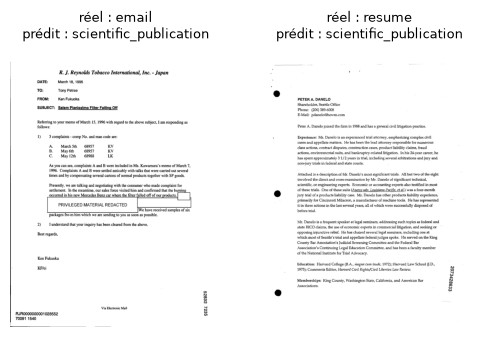

In [6]:
test_df["prédit"] = predictions["caractères"]
erreurs = test_df[test_df["label"] != test_df["prédit"]]

fig, axes = plt.subplots(1, len(erreurs), figsize=(3 * len(erreurs), 4), squeeze=False)
for ax, (_, erreur) in zip(axes[0], erreurs.iterrows()):
    ax.imshow(Image.open(erreur["filepath"]), cmap="gray")
    ax.set_title(f"réel : {erreur['label']}\nprédit : {erreur['prédit']}", fontsize=9)
    ax.axis("off")
plt.show()